In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import ks_2samp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from river import drift

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True

RANDOM_SEED = 42

In [2]:

rng = np.random.default_rng(RANDOM_SEED)

X_train = rng.normal(0, 1, size=(5000, 2))

logits = 3 * X_train[:, 0] + 1.5 * X_train[:, 1]
probs = 1 / (1 + np.exp(-logits))

y_train = rng.binomial(1, probs)

model = LogisticRegression(random_state=42)
model.fit(X_train, y_train)

print("Training accuracy:", round(model.score(X_train, y_train), 3))
print("Coefficients:", model.coef_)

Training accuracy: 0.848
Coefficients: [[2.89192951 1.47795057]]


In [3]:

def simulate_stream(scenario, seed=123):
    rng = np.random.default_rng(seed)
    records = []

    for day in range(1, 101):
        X = rng.normal(0, 1, size=(200, 2))

        beta = 3.0

        if day >= 51:
            if scenario == "feature_drift":
                X[:, 0] += 1.5

            elif scenario == "concept_drift":
                beta = -3.0

        logits = beta * X[:, 0] + 1.5 * X[:, 1]
        p = 1 / (1 + np.exp(-logits))
        y = rng.binomial(1, p)

        predictions = model.predict(X)

        for i in range(len(X)):
            records.append({
                "day": day,
                "x1": X[i, 0],
                "x2": X[i, 1],
                "y_true": y[i],
                "y_pred": predictions[i],
                "error": int(y[i] != predictions[i])
            })

    return pd.DataFrame(records)


feature_data = simulate_stream("feature_drift")
concept_data = simulate_stream("concept_drift")

print("Feature drift dataset:", feature_data.shape)
print("Concept drift dataset:", concept_data.shape)

Feature drift dataset: (20000, 6)
Concept drift dataset: (20000, 6)


In [4]:

def calculate_psi(reference, current, n_bins=10):
    # Fixed bin boundaries from the reference data
    edges = np.quantile(
        reference,
        np.linspace(0, 1, n_bins + 1)
    )

    edges[0] = -np.inf
    edges[-1] = np.inf

    # Avoid duplicate quantile boundaries
    edges = np.unique(edges)

    ref_counts, _ = np.histogram(reference, bins=edges)
    cur_counts, _ = np.histogram(current, bins=edges)

    ref_pct = ref_counts / ref_counts.sum()
    cur_pct = cur_counts / cur_counts.sum()

    # Smoothing prevents log(0)
    epsilon = 1e-6

    ref_pct = np.maximum(ref_pct, epsilon)
    cur_pct = np.maximum(cur_pct, epsilon)

    # Renormalize after smoothing
    ref_pct /= ref_pct.sum()
    cur_pct /= cur_pct.sum()

    psi = np.sum(
        (cur_pct - ref_pct) *
        np.log(cur_pct / ref_pct)
    )

    return psi


# Quick check
reference = X_train[:, 0]

print("Same distribution PSI:",
      calculate_psi(reference, reference))

print("Shifted distribution PSI:",
      calculate_psi(reference, reference + 1.5))

Same distribution PSI: 0.0
Shifted distribution PSI: 2.058831171683359


In [5]:

def run_detectors(data, reference):
    adwin = drift.ADWIN(delta=0.002)

    page_hinkley = drift.PageHinkley(
        min_instances=100,
        delta=0.005,
        threshold=30,
        mode="up"
    )

    results = []

    for day, batch in data.groupby("day", sort=True):

        current = batch["x1"].to_numpy()

        # Batch-based detectors
        ks = ks_2samp(reference, current)
        psi = calculate_psi(reference, current)

        # Stream-based detectors
        adwin_alert = False
        ph_alert = False

        for x in current:
            adwin.update(float(x))
            if adwin.drift_detected:
                adwin_alert = True

        for error in batch["error"]:
            page_hinkley.update(float(error))
            if page_hinkley.drift_detected:
                ph_alert = True

        results.append({
            "day": day,
            "accuracy": 1 - batch["error"].mean(),
            "ks_pvalue": ks.pvalue,
            "psi": psi,
            "ks_alert": ks.pvalue < 0.05,
            "psi_alert": psi > 0.2,
            "adwin_alert": adwin_alert,
            "ph_alert": ph_alert
        })

    return pd.DataFrame(results)


feature_results = run_detectors(
    feature_data, X_train[:, 0]
)

concept_results = run_detectors(
    concept_data, X_train[:, 0]
)

print("Feature drift results:")
print(feature_results.tail())

print("\nConcept drift results:")
print(concept_results.tail())

Feature drift results:
    day  accuracy     ks_pvalue       psi  ks_alert  psi_alert  adwin_alert  \
95   96     0.925  1.183216e-56  1.929438      True       True        False   
96   97     0.920  8.721837e-55  2.774155      True       True        False   
97   98     0.930  2.050361e-70  2.318268      True       True        False   
98   99     0.950  3.586535e-56  2.788216      True       True        False   
99  100     0.910  9.884545e-64  1.964232      True       True        False   

    ph_alert  
95     False  
96     False  
97     False  
98     False  
99     False  

Concept drift results:
    day  accuracy  ks_pvalue       psi  ks_alert  psi_alert  adwin_alert  \
95   96     0.320   0.387315  0.058053     False      False        False   
96   97     0.315   0.798575  0.039066     False      False        False   
97   98     0.405   0.082617  0.084437     False      False        False   
98   99     0.325   0.944561  0.026031     False      False        False   
99  100 

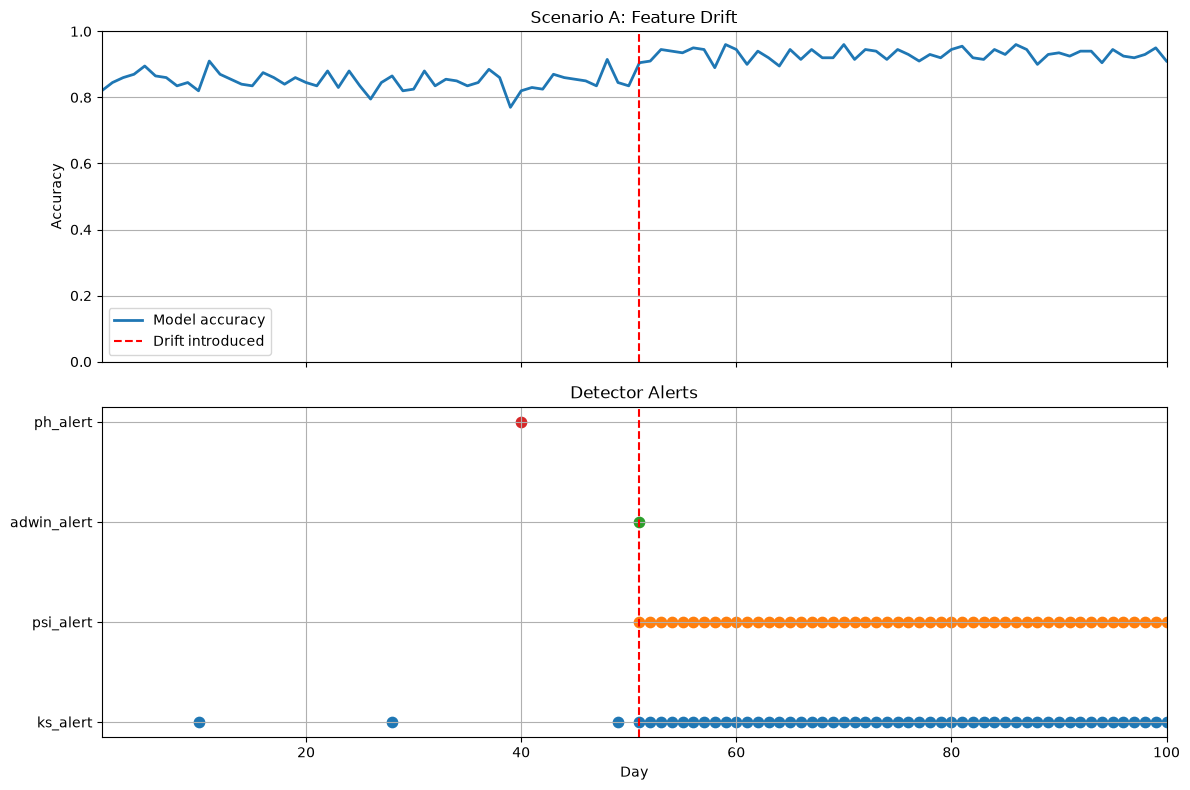

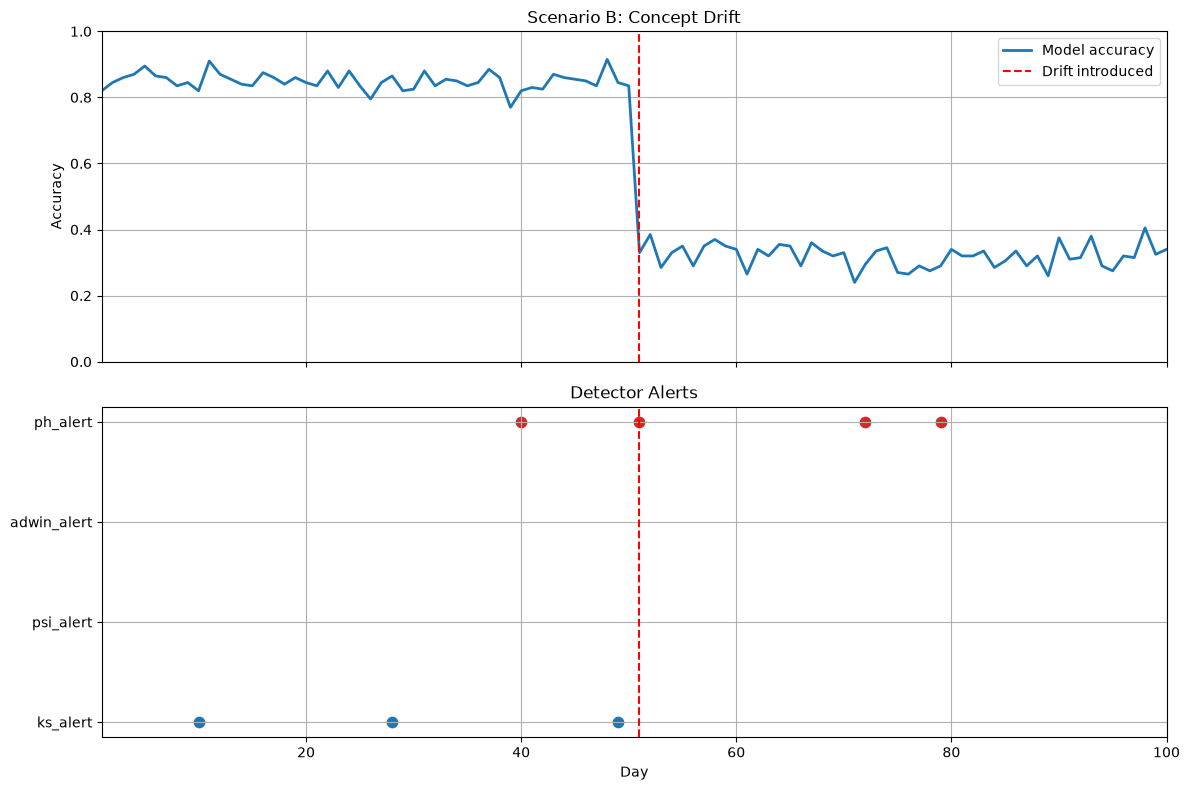

In [6]:

def plot_detector_results(results, title):
    fig, axes = plt.subplots(
        2, 1, figsize=(12, 8), sharex=True
    )

    axes[0].plot(
        results["day"],
        results["accuracy"],
        label="Model accuracy",
        linewidth=2
    )

    axes[0].axvline(
        51, color="red", linestyle="--",
        label="Drift introduced"
    )

    axes[0].set_ylabel("Accuracy")
    axes[0].set_ylim(0, 1)
    axes[0].set_title(title)
    axes[0].legend()

    detectors = [
        "ks_alert",
        "psi_alert",
        "adwin_alert",
        "ph_alert"
    ]

    for i, detector in enumerate(detectors):
        alert_days = results.loc[
            results[detector], "day"
        ]

        axes[1].scatter(
            alert_days,
            [i] * len(alert_days),
            s=55,
            label=detector
        )

    axes[1].axvline(
        51, color="red", linestyle="--"
    )

    axes[1].set_yticks(range(len(detectors)))
    axes[1].set_yticklabels(detectors)
    axes[1].set_xlabel("Day")
    axes[1].set_title("Detector Alerts")
    axes[1].set_xlim(1, 100)

    plt.tight_layout()
    plt.show()


plot_detector_results(
    feature_results, "Scenario A: Feature Drift"
)

plot_detector_results(
    concept_results, "Scenario B: Concept Drift"
)

In [7]:

def summarize_alerts(results, scenario):
    detectors = [
        "ks_alert",
        "psi_alert",
        "adwin_alert",
        "ph_alert"
    ]

    summary = []

    for detector in detectors:
        false_alerts = results.loc[
            (results["day"] < 51) &
            (results[detector]),
            "day"
        ]

        after_drift = results.loc[
            (results["day"] >= 51) &
            (results[detector]),
            "day"
        ]

        first_detection = (
            int(after_drift.iloc[0])
            if len(after_drift) else None
        )

        summary.append({
            "scenario": scenario,
            "detector": detector,
            "pre_drift_alert_days": len(false_alerts),
            "first_post_drift_alert": first_detection,
            "detection_delay_days": (
                first_detection - 51
                if first_detection is not None else None
            )
        })

    return pd.DataFrame(summary)


summary = pd.concat([
    summarize_alerts(
        feature_results, "Feature drift"
    ),
    summarize_alerts(
        concept_results, "Concept drift"
    )
], ignore_index=True)

print(summary.to_string(index=False))

     scenario    detector  pre_drift_alert_days  first_post_drift_alert  detection_delay_days
Feature drift    ks_alert                     3                    51.0                   0.0
Feature drift   psi_alert                     0                    51.0                   0.0
Feature drift adwin_alert                     0                    51.0                   0.0
Feature drift    ph_alert                     1                     NaN                   NaN
Concept drift    ks_alert                     3                     NaN                   NaN
Concept drift   psi_alert                     0                     NaN                   NaN
Concept drift adwin_alert                     0                     NaN                   NaN
Concept drift    ph_alert                     1                    51.0                   0.0
